# Evaluate Ensemble: Band-Only Baseline

B Steele, Colorado State University, ROSSyndicate — last updated Oct 8, 2026

**Pipeline step 05b · Python · run from `regional_clarity/`**

- **Purpose:** Evaluate the band-only ensemble exactly as `05_evaluate_ensemble.ipynb` evaluates production, and compare the two.
- **Inputs:** `aquamatch_files/base_with_splits.parquet`, `states.gdb`, `huc4_filtered.gdb`; `xg_models/v3_band_only/seed*/`; `xg_models/v3_production/` (for comparison).
- **Outputs:** `xg_models/v3_band_only/ensemble_mean_abs_shap.csv`.
- **Previous:** [04b · Make models (band-only)](04b_make_models_band_only.ipynb)
- **Next:** [06b · Test-set sensitivity (band-only)](06b_test_set_sensitivity_band_only.ipynb)

The band-only ensemble (`04b_make_models_band_only.ipynb`) is the production pipeline with its candidate pool restricted to scene-derived information: the seven harmonized bands, the nine spectral indices, and the LaSRC flag. Every other choice (data, holdout, per-seed folds, tuning, elimination, ensembling) is identical, so differences from `05_evaluate_ensemble.ipynb` isolate the contribution of the site characteristics and antecedent weather.

Every section below repeats its counterpart in `05` on the band-only models. The final section compares the two ensembles directly.

## Setup

Import libraries and the shared modeling modules. Then rebuild the modeling table the same way `04_make_models.ipynb` does (spectral indices, coarsened site features, and the 10 seeds' CV arrangements) and pull out the fixed holdout.

In [1]:
import json
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb

sys.path.insert(0, str(Path("python").resolve()))
import features
import metrics as M
import model_xgb
import spatial_cv

AQUAMATCH_DIR = Path("aquamatch_files")
MODELS_DIR = Path("xg_models") / "v3_band_only"
PRODUCTION_DIR = Path("xg_models") / "v3_production"
TARGET = "harmonized_value"
MOD = model_xgb
SEEDS = list(range(601, 611))

ROSS_LT_PAL = ["#002EA3", "#E70870", "#256BF5", "#745CFB", "#1E4D2B", "#56104E"]

df = pd.read_parquet(AQUAMATCH_DIR / "base_with_splits.parquet")
df = features.add_spectral_indices(df)
df = features.coarsen_site_features(df)
df = spatial_cv.build_splits(df, ensemble_seeds=SEEDS)
holdout = df[df["is_holdout"]].reset_index(drop=True)
print(f"holdout: {len(holdout):,} rows")

/Users/steeleb/Documents/GitHub/regional-clarity-RS-model/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


holdout: 2,206 rows


## Assemble the ensemble

Each seed independently selected its own features and hyperparameters and produced holdout predictions from its own 4 fold models. The band-only prediction for a given (site, date) is the plain average across all 10 seeds x 4 folds — 40 models — with no per-seed weighting.

In [2]:
all_rows = []
for seed in SEEDS:
    all_rows.append(pd.read_parquet(MODELS_DIR / f"seed{seed}" / "holdout_predictions.parquet"))
all_preds = pd.concat(all_rows, ignore_index=True)

ensemble_pred = all_preds.groupby(["siteSR_id", "date"]).agg(
    y=("y", "first"), pred=("pred", "mean"), HUC4=("HUC4", "first"), HUC8=("HUC8", "first")).reset_index()
ensemble_metrics = M.all_metrics(ensemble_pred["y"], ensemble_pred["pred"])
print(f"band-only ensemble (10 seeds x xgboost, 40 models): {ensemble_metrics}")

band-only ensemble (10 seeds x xgboost, 40 models): {'rmse': 1.3557761741752319, 'mae': 1.0021014013283251, 'mape': 0.434300934495605, 'bias': 0.08206204905480034, 'p_bias': 2.5441615587279007, 'smape': 0.3361746473727103, 'r2': 0.5647790298588051, 'n': 1833}


## Predicted vs. observed

Ensemble predictions against observed Secchi depth for every holdout observation, with the dashed 1:1 line and the overall holdout metrics in the title.

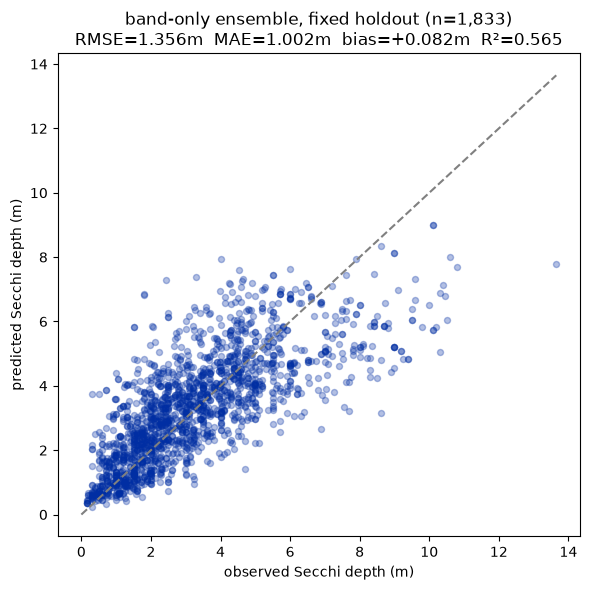

In [3]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(ensemble_pred["y"], ensemble_pred["pred"], alpha=0.3, s=19, color=ROSS_LT_PAL[0])
lims = [0, max(ensemble_pred["y"].max(), ensemble_pred["pred"].max())]
ax.plot(lims, lims, ls="--", color="grey")
ax.set_xlabel("observed Secchi depth (m)")
ax.set_ylabel("predicted Secchi depth (m)")
ax.set_title(f"band-only ensemble, fixed holdout (n={len(ensemble_pred):,})\n"
             f"RMSE={ensemble_metrics['rmse']:.3f}m  MAE={ensemble_metrics['mae']:.3f}m  "
             f"bias={ensemble_metrics['bias']:+.3f}m  R²={ensemble_metrics['r2']:.3f}")
plt.tight_layout()
plt.show()

## Performance by HUC8

Reported at the HUC8 level, the split's actual unit (see `03_split_data.ipynb`), rather than aggregated up to HUC4 — a HUC4 can straddle both the holdout and multiple CV folds, but every HUC8 sits entirely on one side. There is no HUC8 boundary-polygon layer on hand, so rather than a choropleth, each holdout site is plotted individually, colored by its own HUC8 group's error, with HUC4 boundaries drawn only as spatial context.

First, tabulate holdout error metrics for each HUC8, sorted from highest to lowest RMSE.

In [4]:
huc8_metrics = (ensemble_pred.groupby("HUC8")
                .apply(lambda g: pd.Series({**M.all_metrics(g["y"], g["pred"]), "HUC4": g["HUC4"].iloc[0]}),
                       include_groups=False)
                .reset_index()
                .sort_values("rmse", ascending=False))
huc8_metrics

/Users/steeleb/Documents/GitHub/regional-clarity-RS-model/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3015: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/Users/steeleb/Documents/GitHub/regional-clarity-RS-model/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2888: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/steeleb/Documents/GitHub/regional-clarity-RS-model/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2888: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


,HUC8,rmse,mae,mape,bias,p_bias,smape,r2,n,HUC4
13,11020003,2.575900,2.575900,0.328140,-2.575900,-32.814015,0.392545,NaN,1,1102
40,17050203,2.442455,1.896136,0.840279,0.346922,10.117307,0.549962,0.731862,10,1705
9,10180002,2.373170,2.039294,0.587920,2.039294,54.072202,0.422218,0.005075,7,1018
32,15040004,2.316454,1.944365,1.722160,1.889463,119.216111,0.757300,0.013969,53,1504
35,17010303,2.062336,1.606101,0.288040,-0.830366,-14.290375,0.288472,0.469413,165,1701
4,10060007,2.049805,1.926145,0.783378,1.926145,75.535116,0.546477,0.610905,4,1006
3,10030205,1.799551,1.799551,0.378853,-1.799551,-37.885294,0.467389,NaN,1,1003
1,10020007,1.678424,1.284565,0.192327,-0.033015,-0.468967,0.183077,0.486279,10,1002
34,17010213,1.669599,1.436383,0.566284,1.385614,37.796345,0.371360,0.228334,5,1701
22,14020005,1.610367,1.482303,0.517115,-0.374115,-8.255579,0.422595,0.876132,6,1402


Then map the same results. Each holdout site is colored by its HUC8's RMSE (left) and bias (right; red is overprediction, blue is underprediction).

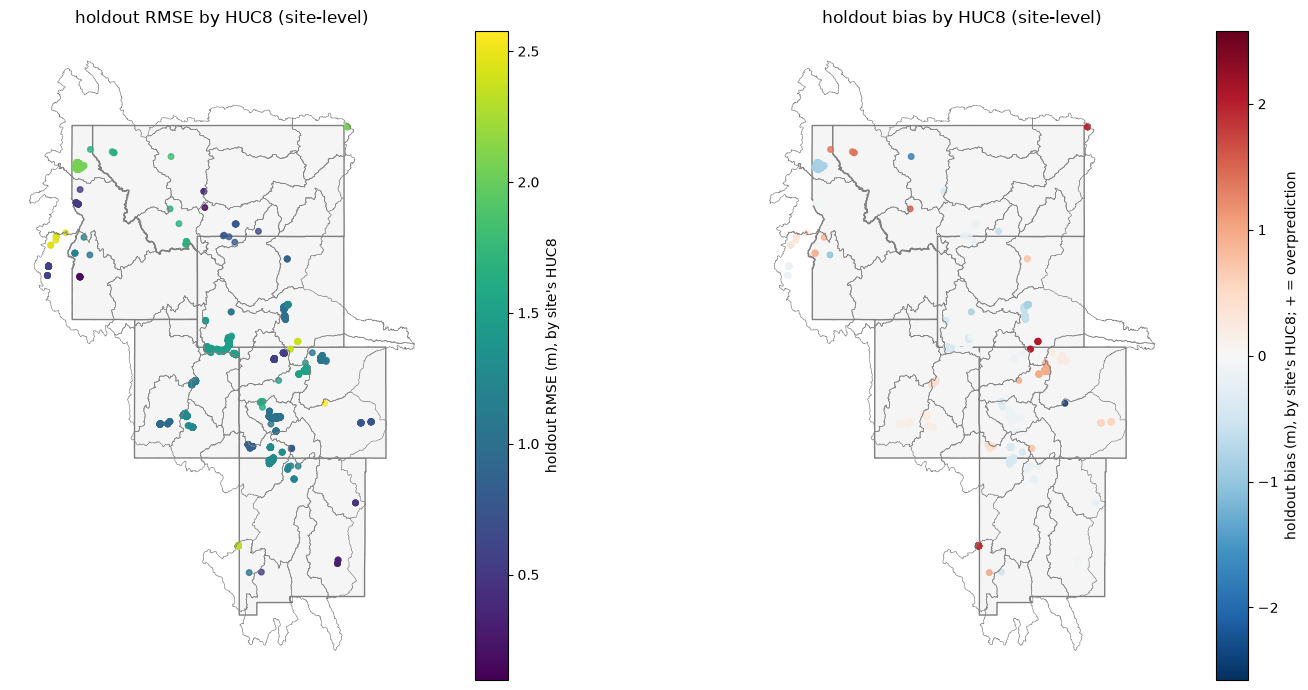

In [5]:
states = gpd.read_file(AQUAMATCH_DIR / "states.gdb", layer="states")
huc4s = gpd.read_file(AQUAMATCH_DIR / "huc4_filtered.gdb", layer="huc4_filtered")

latlon_lookup = df[["siteSR_id", "date", "lat", "lon"]].drop_duplicates(subset=["siteSR_id", "date"])
site_metrics = (ensemble_pred.merge(latlon_lookup, on=["siteSR_id", "date"], how="left")
                .merge(huc8_metrics[["HUC8", "rmse", "bias"]], on="HUC8", how="left"))
site_gdf = gpd.GeoDataFrame(site_metrics, geometry=gpd.points_from_xy(site_metrics.lon, site_metrics.lat),
                            crs="EPSG:4326").to_crs(huc4s.crs)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax = axes[0]
states.plot(ax=ax, color="whitesmoke", edgecolor="grey")
huc4s.boundary.plot(ax=ax, color="grey", linewidth=0.4)
site_gdf.plot(ax=ax, column="rmse", cmap="viridis", legend=True, markersize=16, alpha=0.8,
              legend_kwds={"label": "holdout RMSE (m), by site's HUC8"})
ax.set_title("holdout RMSE by HUC8 (site-level)")
ax.set_axis_off()

ax = axes[1]
states.plot(ax=ax, color="whitesmoke", edgecolor="grey")
huc4s.boundary.plot(ax=ax, color="grey", linewidth=0.4)
vmax = site_gdf["bias"].abs().max()
site_gdf.plot(ax=ax, column="bias", cmap="RdBu_r", vmin=-vmax, vmax=vmax, legend=True, markersize=16, alpha=0.8,
              legend_kwds={"label": "holdout bias (m), by site's HUC8; + = overprediction"})
ax.set_title("holdout bias by HUC8 (site-level)")
ax.set_axis_off()

fig.tight_layout()
plt.show()

### Predicted vs. observed in the worst-performing HUC8s

Small multiples for the worst-RMSE HUC8s (restricted to `n >= 15` so this isn't dominated by tiny, noisy groups), each panel on its own 1:1 line.

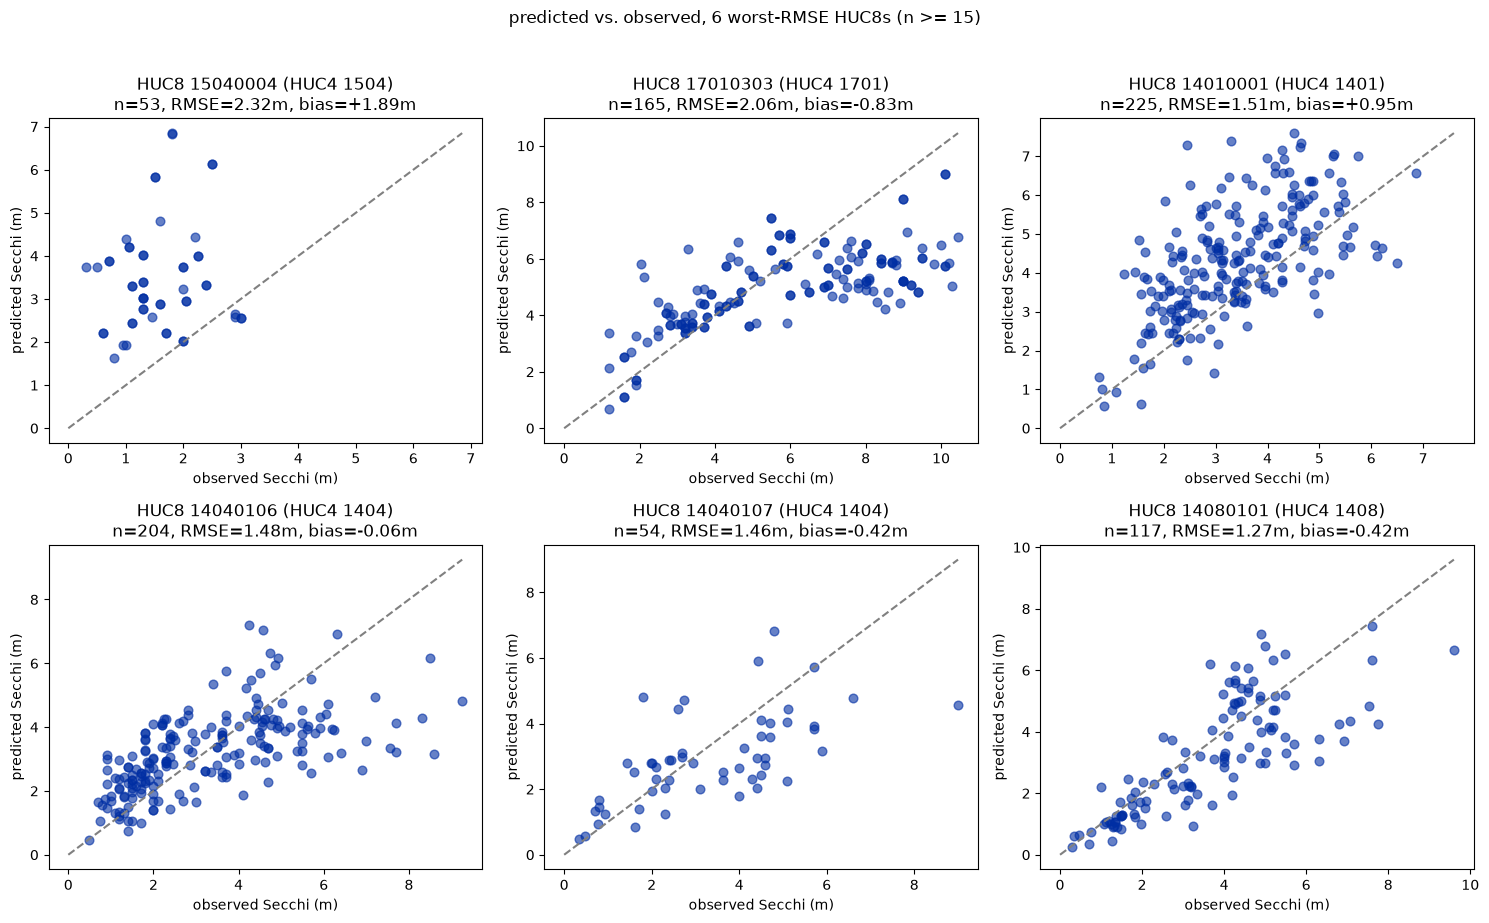

In [6]:
N_WORST = 6
MIN_N = 15
worst_huc8 = huc8_metrics[huc8_metrics["n"] >= MIN_N].sort_values("rmse", ascending=False).head(N_WORST)

n_panels = len(worst_huc8)
ncols = 3
nrows = -(-n_panels // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows), squeeze=False)

for ax, (_, row) in zip(axes.flat, worst_huc8.iterrows()):
    sub = ensemble_pred[ensemble_pred["HUC8"] == row["HUC8"]]
    ax.scatter(sub["y"], sub["pred"], alpha=0.6, s=39, color=ROSS_LT_PAL[0])
    lims = [0, max(sub["y"].max(), sub["pred"].max())]
    ax.plot(lims, lims, ls="--", color="grey")
    ax.set_title(f"HUC8 {row['HUC8']} (HUC4 {row['HUC4']})\n"
                 f"n={int(row['n'])}, RMSE={row['rmse']:.2f}m, bias={row['bias']:+.2f}m")
    ax.set_xlabel("observed Secchi (m)")
    ax.set_ylabel("predicted Secchi (m)")

for ax in axes.flat[n_panels:]:
    ax.set_visible(False)

fig.suptitle(f"predicted vs. observed, {N_WORST} worst-RMSE HUC8s (n >= {MIN_N})", y=1.02)
fig.tight_layout()
plt.show()

## Seed-to-seed spread

As in `05`, all spread across the 10 ensemble members is seed-driven by construction.

typical per-point std across the 10 seeds: 0.0883m (median 0.0779m)
seed-vs-seed pairwise corr: mean=0.9981, min=0.9965, max=0.9992


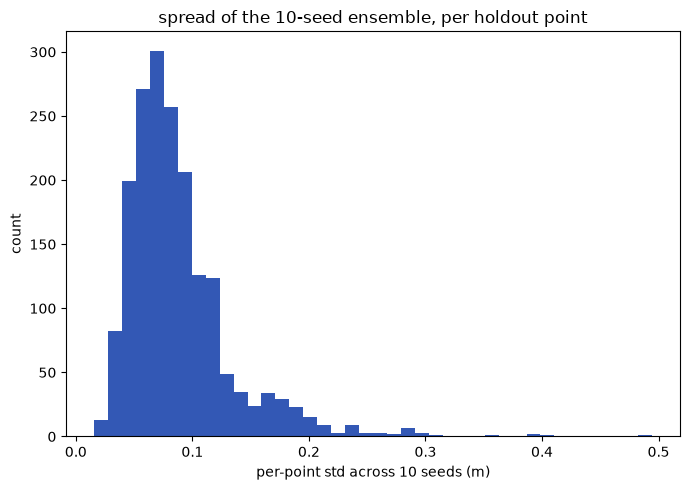

In [7]:
pivot = all_preds.pivot_table(index=["siteSR_id", "date"], columns="seed", values="pred")
per_point_std = pivot.std(axis=1)
print(f"typical per-point std across the 10 seeds: {per_point_std.mean():.4f}m "
      f"(median {per_point_std.median():.4f}m)")

seed_corrs = []
for i, s1 in enumerate(pivot.columns):
    for s2 in pivot.columns[i + 1:]:
        seed_corrs.append(np.corrcoef(pivot[s1], pivot[s2])[0, 1])
print(f"seed-vs-seed pairwise corr: mean={np.mean(seed_corrs):.4f}, "
      f"min={np.min(seed_corrs):.4f}, max={np.max(seed_corrs):.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(per_point_std, bins=40, color=ROSS_LT_PAL[0], alpha=0.8)
ax.set_xlabel("per-point std across 10 seeds (m)")
ax.set_ylabel("count")
ax.set_title("spread of the 10-seed ensemble, per holdout point")
plt.tight_layout()
plt.show()

## SHAP feature attribution

Each seed selects its own final feature set independently (backward elimination converges to a different set per seed). Cross-seed attribution comparisons are restricted to the **unanimous core** — features present in every seed's own final set. Each seed's own final feature set and gap-aware-tuned hyperparameters are reused unchanged (no re-selection/re-tuning), retrained on that seed's 4 folds, and explained with `shap.TreeExplainer` on the shared holdout.

The chunk below retrains each seed's fold models, computes SHAP values on the holdout, averages them across the four folds, and identifies the unanimous core.

In [8]:
def load_seed_config(seed):
    with open(MODELS_DIR / f"seed{seed}" / "backward_elim_summary.json") as fh:
        feats = json.load(fh)["final_features"]
    with open(MODELS_DIR / f"seed{seed}" / "final_tune_xgboost.json") as fh:
        params = json.load(fh)["best_params"]
    return feats, params


per_seed = {}
for seed in SEEDS:
    folds = spatial_cv.build_folds(df, seed)
    feats, params = load_seed_config(seed)
    print(f"seed{seed}: training 4 folds + SHAP on {len(holdout)}-row holdout ({len(feats)} feats)")
    fold_shaps = []
    for f in folds:
        model = MOD.train_fold_models([f], feats, TARGET, params)[0]
        explainer = shap.TreeExplainer(model)
        sv = explainer.shap_values(xgb.DMatrix(holdout[feats]))
        fold_shaps.append(np.asarray(sv))
    mean_shap = np.mean(fold_shaps, axis=0)
    per_seed[seed] = pd.DataFrame(mean_shap, columns=feats)

unanimous = None
for feats_df in per_seed.values():
    cols = set(feats_df.columns)
    unanimous = cols if unanimous is None else (unanimous & cols)
unanimous = sorted(unanimous)
print(f"\nunanimous core ({len(unanimous)} features): {unanimous}")

seed601: training 4 folds + SHAP on 2206-row holdout (12 feats)


seed602: training 4 folds + SHAP on 2206-row holdout (13 feats)


seed603: training 4 folds + SHAP on 2206-row holdout (13 feats)


seed604: training 4 folds + SHAP on 2206-row holdout (12 feats)


seed605: training 4 folds + SHAP on 2206-row holdout (13 feats)


...

seed607: training 4 folds + SHAP on 2206-row holdout (13 feats)


seed608: training 4 folds + SHAP on 2206-row holdout (13 feats)


seed609: training 4 folds + SHAP on 2206-row holdout (13 feats)


seed610: training 4 folds + SHAP on 2206-row holdout (13 feats)



unanimous core (11 features): ['BG', 'BR', 'MNDWI', 'NDSSI', 'NDWI', 'NR', 'atm_corr_LaSRC', 'fai', 'green_corr7', 'nir_corr7', 'temp_corr7']


Average the SHAP values across seeds for the unanimous-core features, and rank the features by mean absolute SHAP (the average magnitude of each feature's contribution to a prediction, in meters). Every candidate here is optical, so the category split is 100% optical by construction; it is kept so the saved table has the same columns as production's. The ranking is saved to `ensemble_mean_abs_shap.csv`, which `07b_regional_application_band_only.Rmd` uses to weight the area-of-applicability check.

top 8 features by mean|SHAP|:
green_corr7    0.5265
BG             0.4868
MNDWI          0.2476
BR             0.2387
fai            0.2061
NR             0.1112
nir_corr7      0.0837
temp_corr7     0.0678
dtype: float32

share of total mean|SHAP| attribution by category:
optical    100.0
dtype: float32


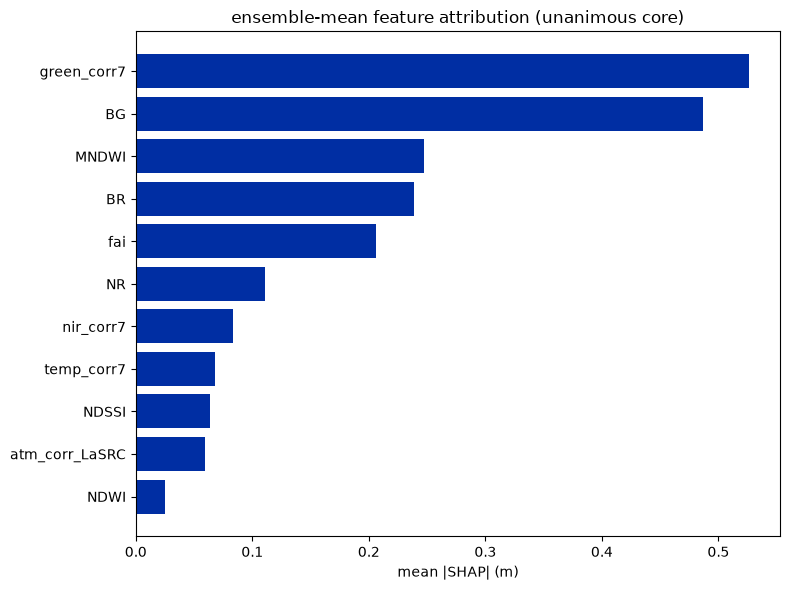

In [9]:
long_rows = []
for seed, feats_df in per_seed.items():
    sub = feats_df[unanimous].copy()
    sub["seed"] = seed
    sub["_row"] = np.arange(len(holdout))
    long_rows.append(sub)
long_df = pd.concat(long_rows, ignore_index=True)

ensemble_mean_shap = long_df.groupby("_row")[unanimous].mean().sort_index()

SITE_COLS = {"elevation_m", "catchment_area_sqkm", "pct_impervious_2006", "pct_urban_2006",
             "pct_forest_2006", "pct_cropland_2006", "pct_wetland_2006", "shore_flag"}
WEATHER_PREFIXES = ("precip_mm_prev", "tmax_degC_prev", "tmean_degC_prev", "tmin_degC_prev", "srad_Wm2_prev")


def categorize(feat):
    if feat in SITE_COLS:
        return "site"
    if feat.startswith(WEATHER_PREFIXES):
        return "weather"
    return "optical"


mean_abs_shap = ensemble_mean_shap.abs().mean().sort_values(ascending=False)
cat_share = mean_abs_shap.groupby(categorize).sum() / mean_abs_shap.sum() * 100
(mean_abs_shap.rename("mean_abs_shap").rename_axis("feature").to_frame()
 .assign(category=lambda d: d.index.map(categorize))
 .to_csv(MODELS_DIR / "ensemble_mean_abs_shap.csv"))

print("top 8 features by mean|SHAP|:")
print(mean_abs_shap.head(8).round(4))
print("\nshare of total mean|SHAP| attribution by category:")
print(cat_share.round(1))

fig, ax = plt.subplots(figsize=(8, 6))
colors = mean_abs_shap.index.map(lambda f: {"optical": ROSS_LT_PAL[0], "site": ROSS_LT_PAL[1],
                                             "weather": ROSS_LT_PAL[2]}[categorize(f)])
ax.barh(mean_abs_shap.index[::-1], mean_abs_shap.values[::-1], color=colors[::-1])
ax.set_xlabel("mean |SHAP| (m)")
ax.set_title("ensemble-mean feature attribution (unanimous core)")
plt.tight_layout()
plt.show()

## Per-HUC8 SHAP

Break the attribution down by HUC8: the mean absolute SHAP of each unanimous-core feature within each holdout HUC8.

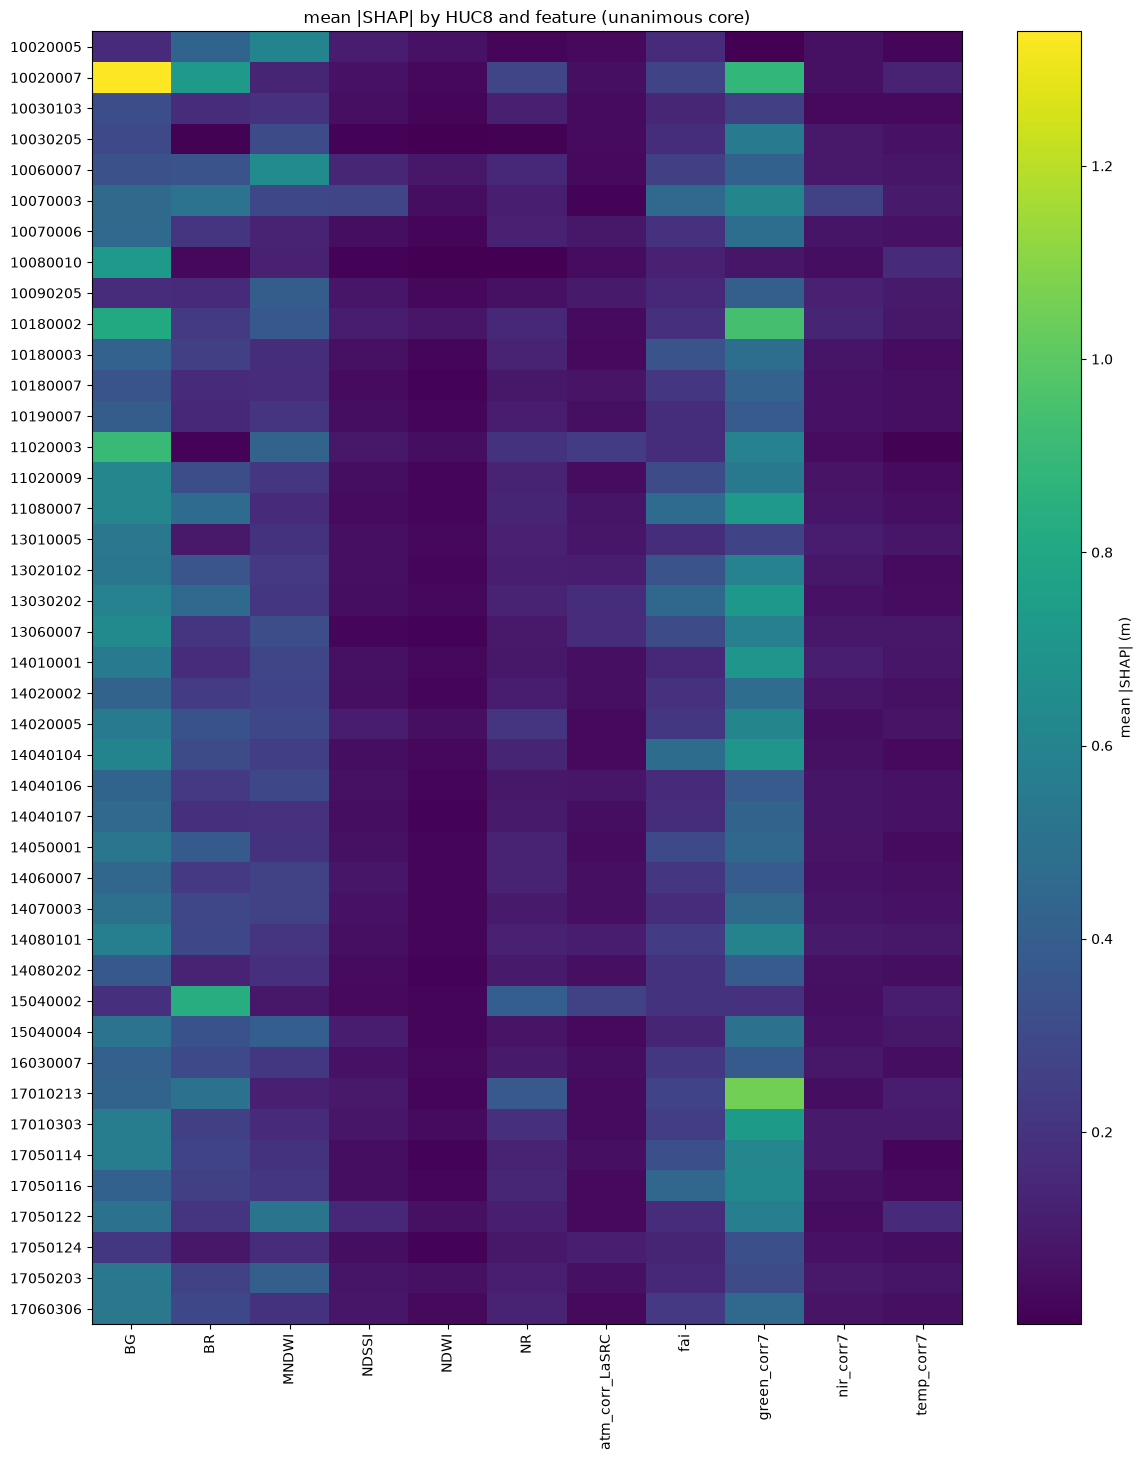

In [10]:
shap_with_huc8 = ensemble_mean_shap.copy()
shap_with_huc8["HUC8"] = holdout["HUC8"].values
huc8_shap = shap_with_huc8.groupby("HUC8")[unanimous].apply(lambda g: g.abs().mean())

if "catchment_area_sqkm" in huc8_shap.columns:
    print("catchment_area_sqkm mean|SHAP| by HUC8 (top 5):")
    print(huc8_shap["catchment_area_sqkm"].sort_values(ascending=False).head(5).round(4))

fig, ax = plt.subplots(figsize=(12, max(4, 0.35 * len(huc8_shap))))
im = ax.imshow(huc8_shap.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(unanimous)))
ax.set_xticklabels(unanimous, rotation=90)
ax.set_yticks(range(len(huc8_shap)))
ax.set_yticklabels(huc8_shap.index)
ax.set_title("mean |SHAP| by HUC8 and feature (unanimous core)")
fig.colorbar(im, ax=ax, label="mean |SHAP| (m)")
plt.tight_layout()
plt.show()

## Comparison with production

Both ensembles predict the same 1,833 holdout site-dates. First the overall metrics, then the change in RMSE by HUC8, then attribution for the features the two share.

In [11]:
prod_rows = [pd.read_parquet(PRODUCTION_DIR / f"seed{s}" / "holdout_predictions.parquet") for s in SEEDS]
prod_pred = (pd.concat(prod_rows, ignore_index=True)
             .groupby(["siteSR_id", "date"]).agg(pred=("pred", "mean")).reset_index())
both = ensemble_pred.merge(prod_pred, on=["siteSR_id", "date"], suffixes=("_band", "_prod"), validate="1:1")
assert len(both) == len(ensemble_pred)

pd.DataFrame({"band_only": M.all_metrics(both["y"], both["pred_band"]),
              "production": M.all_metrics(both["y"], both["pred_prod"])}).T.round(3)

,rmse,mae,mape,bias,p_bias,smape,r2,n
band_only,1.356,1.002,0.434,0.082,2.544,0.336,0.565,1833.0
production,1.257,0.941,0.419,0.152,4.724,0.318,0.627,1833.0


Holdout RMSE by HUC8 for both ensembles. Negative ΔRMSE means production (bands + site + weather) is better in that basin. Each holdout site is mapped by its HUC8's ΔRMSE.

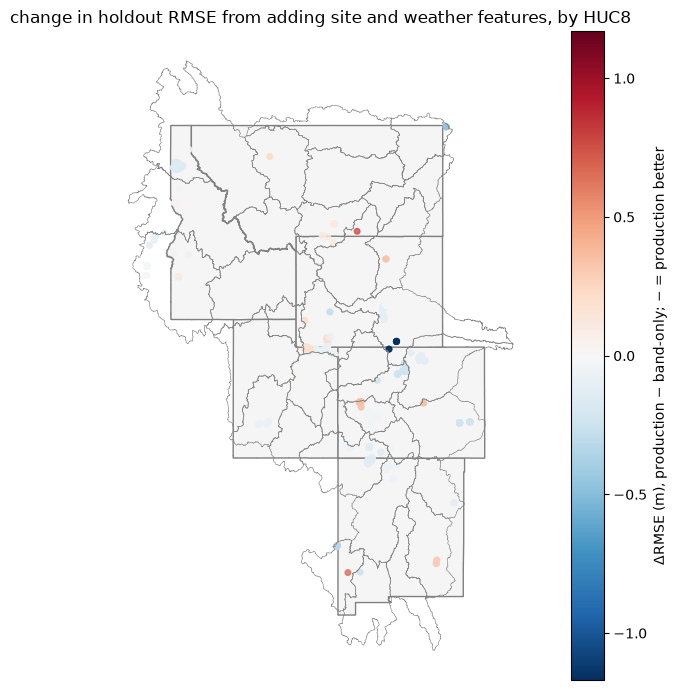

,HUC8,n,HUC4,band_only_rmse,production_rmse,band_only_bias,production_bias,delta_rmse
21,14020002,298,1402,1.017,0.977,-0.124,-0.005,-0.040
20,14010001,225,1401,1.512,1.274,0.950,0.756,-0.238
24,14040106,204,1404,1.475,1.401,-0.059,0.243,-0.074
35,17010303,165,1701,2.062,1.905,-0.830,-0.559,-0.157
29,14080101,117,1408,1.271,1.136,-0.420,-0.000,-0.135
12,10190007,109,1019,1.067,0.943,0.218,-0.069,-0.124
28,14070003,104,1407,1.260,1.269,0.200,0.209,0.009
27,14060007,87,1406,1.123,1.137,0.461,0.614,0.013
37,17050116,74,1705,0.582,0.568,-0.124,0.049,-0.015
26,14050001,74,1405,0.555,0.564,-0.121,-0.108,0.009


In [12]:
huc8_cmp = (both.groupby("HUC8")
            .apply(lambda g: pd.Series({"n": len(g), "HUC4": g["HUC4"].iloc[0],
                                        "band_only_rmse": M.rmse(g["y"], g["pred_band"]),
                                        "production_rmse": M.rmse(g["y"], g["pred_prod"]),
                                        "band_only_bias": M.bias(g["y"], g["pred_band"]),
                                        "production_bias": M.bias(g["y"], g["pred_prod"])}),
                   include_groups=False)
            .reset_index())
huc8_cmp["delta_rmse"] = huc8_cmp["production_rmse"] - huc8_cmp["band_only_rmse"]

site_cmp = (both.merge(latlon_lookup, on=["siteSR_id", "date"], how="left")
            .merge(huc8_cmp[["HUC8", "delta_rmse"]], on="HUC8", how="left"))
site_cmp_gdf = gpd.GeoDataFrame(site_cmp, geometry=gpd.points_from_xy(site_cmp.lon, site_cmp.lat),
                                crs="EPSG:4326").to_crs(huc4s.crs)

fig, ax = plt.subplots(figsize=(8, 7))
states.plot(ax=ax, color="whitesmoke", edgecolor="grey")
huc4s.boundary.plot(ax=ax, color="grey", linewidth=0.4)
vmax = site_cmp_gdf["delta_rmse"].abs().max()
site_cmp_gdf.plot(ax=ax, column="delta_rmse", cmap="RdBu_r", vmin=-vmax, vmax=vmax, legend=True,
                  markersize=16, alpha=0.8,
                  legend_kwds={"label": "ΔRMSE (m), production − band-only; − = production better"})
ax.set_title("change in holdout RMSE from adding site and weather features, by HUC8")
ax.set_axis_off()
fig.tight_layout()
plt.show()

huc8_cmp.sort_values("n", ascending=False).round(3)

Mean |SHAP| for the band-only unanimous core alongside production's, for features in both. A feature that carries much more weight in the band-only model is absorbing signal that production attributes to site or weather features.

In [13]:
prod_shap = pd.read_csv(PRODUCTION_DIR / "ensemble_mean_abs_shap.csv", index_col="feature")
shap_cmp = (mean_abs_shap.rename("band_only").to_frame()
            .join(prod_shap["mean_abs_shap"].rename("production"), how="outer"))
shap_cmp["category"] = shap_cmp.index.map(categorize)
shap_cmp.sort_values("band_only", ascending=False).round(4)

,band_only,production,category
green_corr7,0.5265,0.4630,optical
BG,0.4868,0.4792,optical
MNDWI,0.2476,0.2264,optical
BR,0.2387,0.2525,optical
fai,0.2061,0.1694,optical
NR,0.1112,0.1405,optical
nir_corr7,0.0837,0.0609,optical
temp_corr7,0.0678,0.0679,optical
NDSSI,0.0636,0.0392,optical
atm_corr_LaSRC,0.0593,0.0836,optical
